CSV found: D:\AgriVision\data\splits.csv ['path', 'label', 'split']
          model                                             best_params       MAE      RMSE        R2
0  RandomForest  {'model__max_depth': None, 'model__n_estimators': 300}  1.086456  1.528622  0.961585
1         Lasso                                   {'model__alpha': 0.1}  1.836786  2.465860  0.900037
2         Ridge                                    {'model__alpha': 10}  1.884506  2.484923  0.898485
3        Linear                                                      {}  1.937837  2.516055  0.895925


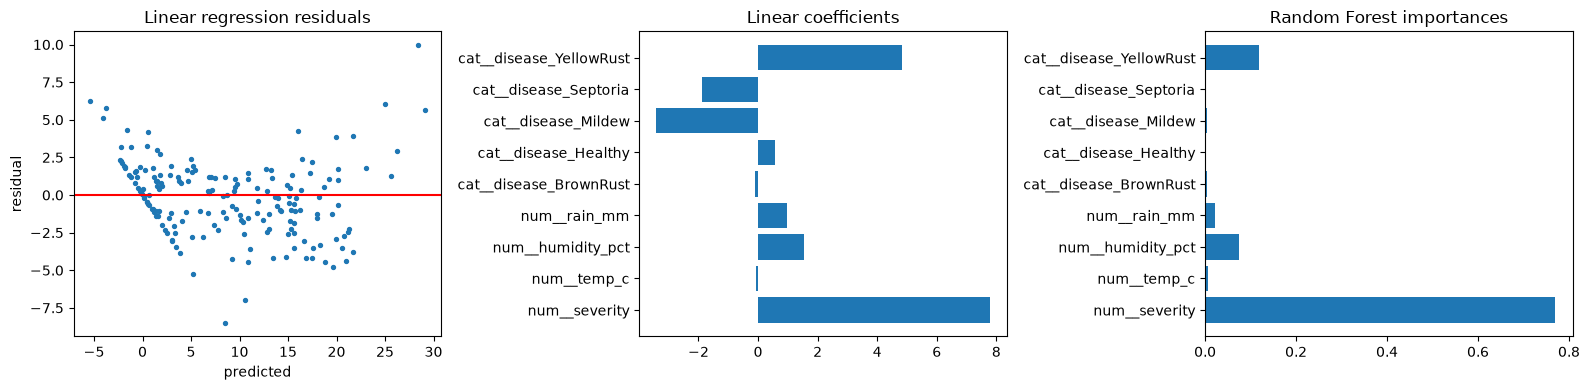

Saved best model: RandomForest


In [ ]:
import numpy as np, pandas as pd, joblib, requests
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rng = np.random.default_rng(42)

# 1. weather: saved CSV -> NASA POWER download -> simulated fallback
WEATHER_CSV = Path(r"D:\AgriVision\data\weather_all_seasons.csv")

def get_weather(lat, lon, start, end):
    r = requests.get("https://power.larc.nasa.gov/api/temporal/daily/point", params={
        "parameters": "T2M,RH2M,PRECTOTCORR", "community": "AG",
        "latitude": lat, "longitude": lon, "start": start, "end": end, "format": "JSON"},
        timeout=60)
    r.raise_for_status()
    d = pd.DataFrame(r.json()["properties"]["parameter"]).rename(columns={
        "T2M": "temp_c", "RH2M": "humidity_pct", "PRECTOTCORR": "rain_mm"})
    return d.replace(-999, np.nan)

weather = None
if WEATHER_CSV.exists():
    weather = pd.read_csv(WEATHER_CSV)
    print("Loaded saved weather:", weather.shape)
else:
    try:
        seasons = [("20211101", "20220430"), ("20221101", "20230430"),
                   ("20231101", "20240430"), ("20241101", "20250430"),
                   ("20251101", "20260430")]
        weather = pd.concat([get_weather(33.68, 73.05, s, e) for s, e in seasons])
        weather.to_csv(WEATHER_CSV)
        print("Downloaded from NASA POWER and saved:", weather.shape)
    except Exception as e:
        print("WARNING: download failed, using simulated weather. Reason:", e)
        n = 906
        weather = pd.DataFrame({
            "temp_c": rng.normal(16, 6, n),
            "humidity_pct": np.clip(rng.normal(55, 15, n), 20, 95),
            "rain_mm": np.clip(rng.gamma(1.2, 1.8, n), 0, 30)})

# 2. build SIMULATED yield-loss labels (no real paired data exists)
MAX_LOSS = {"Healthy": 0, "YellowRust": 50, "BrownRust": 35, "Septoria": 30, "Mildew": 25}

df = weather[["temp_c", "humidity_pct", "rain_mm"]].dropna().reset_index(drop=True)
df["disease"] = rng.choice(list(MAX_LOSS), len(df))
df["severity"] = np.where(df.disease == "Healthy",
                          rng.uniform(0, 2, len(df)), rng.uniform(1, 70, len(df)))

wf = (np.clip(df.humidity_pct / 60, 0.8, 1.3) *
      np.clip(1 + (df.rain_mm - 2) * 0.05, 0.9, 1.2))
df["yield_loss"] = (df.disease.map(MAX_LOSS) * df.severity / 100 * wf
                    + rng.normal(0, 1.0, len(df))).clip(0, 100)

# 3. train/test split and preprocessing
num = ["severity", "temp_c", "humidity_pct", "rain_mm"]
X, y = df[num + ["disease"]], df["yield_loss"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

prep = ColumnTransformer([("num", StandardScaler(), num),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), ["disease"])])

models = {
    "Linear": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"model__alpha": [0.01, 0.1, 1, 10, 100]}),
    "Lasso": (Lasso(max_iter=10000), {"model__alpha": [0.001, 0.01, 0.1, 1]}),
    "RandomForest": (RandomForestRegressor(random_state=42),
                     {"model__n_estimators": [100, 300], "model__max_depth": [None, 8, 16]}),
}

# 4. tune with cross-validation, evaluate on the held-out test set
rows, best = [], {}
for name, (m, grid) in models.items():
    gs = GridSearchCV(Pipeline([("prep", prep), ("model", m)]), grid,
                      cv=5, scoring="neg_mean_absolute_error")
    gs.fit(Xtr, ytr)
    pred = gs.predict(Xte)
    best[name] = gs.best_estimator_
    rows.append({"model": name, "best_params": gs.best_params_,
                 "MAE": mean_absolute_error(yte, pred),
                 "RMSE": float(np.sqrt(mean_squared_error(yte, pred))),
                 "R2": r2_score(yte, pred)})

results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
print(results.to_string())

# 5. plots
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
lin_pred = best["Linear"].predict(Xte)
ax[0].scatter(lin_pred, yte - lin_pred, s=8)
ax[0].axhline(0, color="r")
ax[0].set_title("Linear regression residuals")
ax[0].set_xlabel("predicted")
ax[0].set_ylabel("residual")

names = best["Linear"].named_steps["prep"].get_feature_names_out()
ax[1].barh(names, best["Linear"].named_steps["model"].coef_)
ax[1].set_title("Linear coefficients")
ax[2].barh(names, best["RandomForest"].named_steps["model"].feature_importances_)
ax[2].set_title("Random Forest importances")
plt.tight_layout()
plt.show()

# 6. save the best model and the results table
best_name = results.loc[0, "model"]
Path(r"D:\AgriVision\models").mkdir(exist_ok=True)
joblib.dump(best[best_name], r"D:\AgriVision\models\yield_model.joblib")
results.to_csv(r"D:\AgriVision\data\regression_results.csv", index=False)
print("Saved best model:", best_name)

In [3]:
import os
for root, dirs, files in os.walk(r"D:\AgriVision"):
    dirs[:] = [d for d in dirs if d not in ("venv", ".git", "raw")]
    for fn in files:
        if any(k in fn.lower() for k in ("weather", "nasa", "power", "climate")) or fn.lower().endswith((".xlsx", ".parquet", ".json", ".pkl")):
            print(os.path.join(root, fn))

D:\AgriVision\notebooks\02_weather_data.ipynb
